<a href="https://colab.research.google.com/github/saramarialangner/Machine-Learning/blob/main/2_transformers_from_scratch_SML_AHY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transformers and flow matching from scratch, in JAX

First of all, let's build a transformer from scratch, and teach it to do regression **in context**: every training
example is a *different* function, and the network only sees a handful of noisy points from it. Nothing about
any one function can actually be stored in the weights, but the model has to work it out from its input.

- Earlier task (MLP): Learn a Function.
- Now (Transformer): Learn how to learn a function in context.



In the second half, we will reuse the same network as the velocity field of a **flow matching** model, and draw from the posterior
of functions that are consistent with the data.

The functions are drawn from a Gaussian process with a random lengthscale, so the best possible answer is known
exactly. It will be given by `gp_posterior`.

In [2]:
# !pip install -q jax jaxlib matplotlib

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

print("jax", jax.__version__, "| devices:", jax.devices())

jax 0.11.1 | devices: [CpuDevice(id=0)]


## The data


In [3]:
X_MAX = 2.0
NOISE_STD = 0.05
ELL_MIN, ELL_MAX = 0.2, 1.0


def rbf(x1, x2, ell):
    """x1: (b, n), x2: (b, m), ell: (b,) -> (b, n, m)"""
    return jnp.exp(-0.5 * (x1[:, :, None] - x2[:, None, :]) ** 2 / ell[:, None, None] ** 2)


def sample_tasks(key, batch, n_ctx, n_tgt=32, ell=None, x_tgt=None):
    """Draw `batch` random functions, each observed (with noise) at n_ctx context and n_tgt target points.
    Returns xc, yc: (batch, n_ctx)   xt, yt: (batch, n_tgt)   ell: (batch,)"""
    k_ell, k_xc, k_xt, k_y = jax.random.split(key, 4)
    if ell is None:
        ell = jnp.exp(jax.random.uniform(k_ell, (batch,), minval=np.log(ELL_MIN), maxval=np.log(ELL_MAX)))
    ell = jnp.broadcast_to(jnp.asarray(ell, jnp.float32), (batch,))
    xc = jax.random.uniform(k_xc, (batch, n_ctx), minval=-X_MAX, maxval=X_MAX)
    if x_tgt is None:
        xt = jax.random.uniform(k_xt, (batch, n_tgt), minval=-X_MAX, maxval=X_MAX)
    else:
        xt = jnp.broadcast_to(x_tgt, (batch, x_tgt.shape[-1]))
    x = jnp.concatenate([xc, xt], axis=1)
    K = rbf(x, x, ell) + (NOISE_STD**2 + 1e-5) * jnp.eye(x.shape[1])
    y = jnp.einsum("bij,bj->bi", jnp.linalg.cholesky(K), jax.random.normal(k_y, x.shape))
    return xc, y[:, :n_ctx], xt, y[:, n_ctx:], ell


def gp_posterior(xc, yc, xt, ell):
    """Exact GP prediction at xt given (xc, yc), if you knew the lengthscale.
    Returns mean: (b, n_tgt), cov: (b, n_tgt, n_tgt)"""
    ell = jnp.broadcast_to(jnp.asarray(ell, jnp.float32), (xc.shape[0],))
    Kcc = rbf(xc, xc, ell) + NOISE_STD**2 * jnp.eye(xc.shape[1])
    Ktc = rbf(xt, xc, ell)
    Ktt = rbf(xt, xt, ell) + NOISE_STD**2 * jnp.eye(xt.shape[1])
    A = jnp.linalg.solve(Kcc, jnp.swapaxes(Ktc, 1, 2))
    mean = jnp.einsum("bct,bc->bt", A, yc)
    return mean, Ktt - Ktc @ A


xc, yc, xt, yt, ell = sample_tasks(jax.random.key(0), batch=1000, n_ctx=10)
mean, cov = gp_posterior(xc, yc, xt, ell)

print(f"target variance               : {float(yt.var()):.4f}")   # predict 0 everywhere
print(f"GP error, 10 points, true ell : {float(((mean - yt) ** 2).mean()):.4f}")   # the best you can do

target variance               : 0.9791
GP error, 10 points, true ell : 0.1456


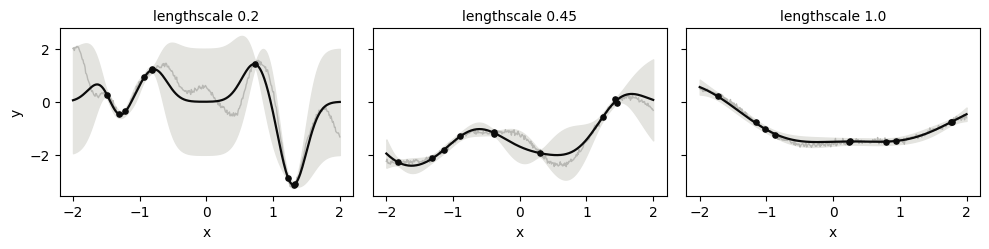

In [4]:
grid = jnp.linspace(-X_MAX, X_MAX, 400)
fig, axes = plt.subplots(1, 3, figsize=(10, 2.6), sharey=True)
for ax, ell_, key in zip(axes, [0.2, 0.45, 1.0], jax.random.split(jax.random.key(1), 3)):
    xc, yc, xt, yt, _ = sample_tasks(key, 1, n_ctx=10, ell=ell_, x_tgt=grid)
    mean, cov = gp_posterior(xc, yc, grid[None], ell_)
    std = jnp.sqrt(jnp.diagonal(cov[0]))
    ax.fill_between(np.array(grid), np.array(mean[0] - 2 * std), np.array(mean[0] + 2 * std), color="#e4e4e0")
    ax.plot(np.array(grid), np.array(yt[0]), color="#b8b8b4", lw=1)
    ax.plot(np.array(grid), np.array(mean[0]), color="#0b0b0b", lw=1.6)
    ax.scatter(np.array(xc[0]), np.array(yc[0]), s=14, color="#0b0b0b", zorder=3)
    ax.set_title(f"lengthscale {ell_}", fontsize=10); ax.set_xlabel("x")
axes[0].set_ylabel("y"); plt.tight_layout(); plt.show()

---
## 1. Attention

Every observed point becomes a token `(x, y, 1)`; every point where you want a prediction is also  a token
`(x, 0, 0)`.

Write multi-head self-attention, `attention(params, h, mask)`, where `mask[i, j]` says whether token `i` may look
at token `j`. Then a transformer block: layer norm, attention, residual, MLP, residual.

Choose the mask.  What are targets allowed to look at? should they receive information from other targets?

## Mathematical Walkthrough of In-Context Attention (I used AI to generate this as a helpful outline for myself)

To help us understand how a Transformer behaves like a meta-learning algorithm, let us trace how the numerical arrays interact step-by-step:

#### Step 1: Embedding Tokens
Every token is mapped into a vector of size $D$. We have two kinds of tokens:
- **Context Tokens**: $\mathbf{t}_{c} = [x_c, y_c, 1]$. We project this into $D$ dimensions.
- **Target Tokens**: $\mathbf{t}_{t} = [x_t, 0, 0]$. We project this into $D$ dimensions.

Combined, our sequence representation is a matrix $\mathbf{H} \in \mathbb{R}^{B \times N \times D}$, where:
- $B$ is the batch size.
- $N = N_{ctx} + N_{tgt}$ is the total sequence length.
- $D$ is the embedding dimension.

#### Step 2: Query, Key, and Value Projection
We project the sequence $\mathbf{H}$ into three representations using matrices $\mathbf{W}_Q, \mathbf{W}_K, \mathbf{W}_V \in \mathbb{R}^{D \times D}$:
$$\mathbf{Q} = \mathbf{H} \mathbf{W}_Q, \quad \mathbf{K} = \mathbf{H} \mathbf{W}_K, \quad \mathbf{V} = \mathbf{H} \mathbf{W}_V$$

To use multiple attention heads, we split the feature dimension $D$ into $H$ heads of dimension $d_k = D / H$. This transforms our matrices into 4D tensors:
$$\mathbf{Q}, \mathbf{K}, \mathbf{V} \in \mathbb{R}^{B \times H \times N \times d_k}$$

#### Step 3: Scaled Dot-Product Attention & Masking
We compute the similarity score between every query and key token. To scale the gradients, we divide by $\sqrt{d_k}$:
$$\mathbf{S} = \frac{\mathbf{Q} \mathbf{K}^T}{\sqrt{d_k}} \in \mathbb{R}^{B \times H \times N \times N}$$

Since target points should not exchange information with each other to avoid cheating during inference, we apply a mask $\mathbf{M}$ where target-to-target connections are filled with $-\infty$:
$$\mathbf{A} = \text{Softmax}(\mathbf{S} + \mathbf{M}) \in \mathbb{R}^{B \times H \times N \times N}$$

#### Step 4: Final Aggregation and Block Updates
We use the attention weights $\mathbf{A}$ to mix the values $\mathbf{V}$, reconstruct our $D$-dimensional representation, and update our representations sequentially:
$$\mathbf{H}^{(1)} = \mathbf{H} + \text{MultiHeadAttention}(\text{LayerNorm}(\mathbf{H}))\mathbf{W}_O$$
$$\mathbf{H}^{(2)} = \mathbf{H}^{(1)} + \text{MLP}(\text{LayerNorm}(\mathbf{H}^{(1)}))$$

In [5]:
import jax
import jax.numpy as jnp

def attention(params, h, mask=None):
    # params: {w_q, w_k, w_v, w_o} and their shape is (depth, num_heads * head_dim)
    # h: (batch, seq_len, depth)
    b, n, d = h.shape
    num_heads = 4
    head_dim = d // num_heads

    q = jnp.dot(h, params['w_q']).reshape(b, n, num_heads, head_dim).swapaxes(1, 2)
    k = jnp.dot(h, params['w_k']).reshape(b, n, num_heads, head_dim).swapaxes(1, 2)
    v = jnp.dot(h, params['w_v']).reshape(b, n, num_heads, head_dim).swapaxes(1, 2)

    scores = jnp.matmul(q, k.swapaxes(-1, -2)) / jnp.sqrt(head_dim)
    if mask is not None:
        scores = jnp.where(mask[:, None, :, :], scores, -1e9)

    attn_weights = jax.nn.softmax(scores, axis=-1)
    out = jnp.matmul(attn_weights, v).swapaxes(1, 2).reshape(b, n, d)
    return jnp.dot(out, params['w_o'])

def transformer_block(params, h, mask=None):
    # layer norm 1
    mean1 = h.mean(axis=-1, keepdims=True)
    var1 = h.var(axis=-1, keepdims=True)
    norm_h = (h - mean1) / jnp.sqrt(var1 + 1e-5) * params['gamma1'] + params['beta1']

    # attention and residual
    h = h + attention(params['attn'], norm_h, mask)

    # layer norm 2
    mean2 = h.mean(axis=-1, keepdims=True)
    var2 = h.var(axis=-1, keepdims=True)
    norm_h = (h - mean2) / jnp.sqrt(var2 + 1e-5) * params['gamma2'] + params['beta2']

    # MLP and residual
    ff = jnp.dot(norm_h, params['w_ff1']) + params['b_ff1']
    ff = jax.nn.relu(ff)
    ff = jnp.dot(ff, params['w_ff2']) + params['b_ff2']

    return h + ff

---
## 2. The transformer

Embed the tokens (a small MLP is fine), stack transformer blocks, and read out a mean and a log-variance at each target.
We will assume a Gaussian negative log-likelihood during training. Some reasonable numbers are width 64, 4 heads, 4 layers.

Each step: get a batch of functions, with a random number of context points between 3 and 30, and 30'ish targets as well.
Feel free to use jax libraries for the optimiser and weight updates (no need to use your solution from the previous tutorial!).
The number of context points changes the shapes, so `jax.jit` recompiles once per value. That's fine, otherwise you'd need to add some padding

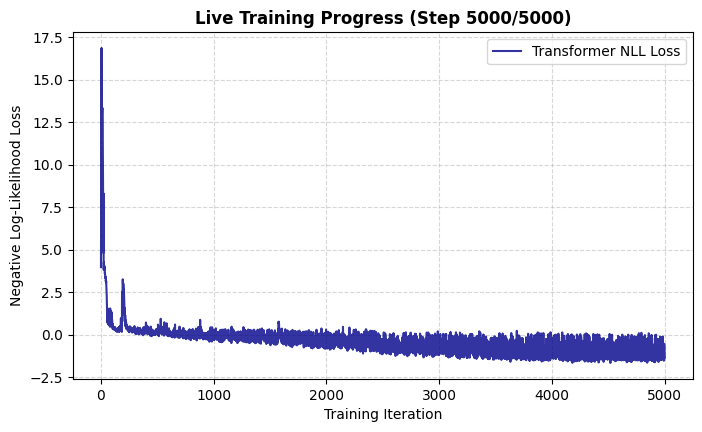

Step    0 | Transformer NLL Loss: 3.9677
Step  200 | Transformer NLL Loss: 2.5847
Step  400 | Transformer NLL Loss: 0.5488
Step  600 | Transformer NLL Loss: 0.0324
Step  800 | Transformer NLL Loss: 0.1237
Step 1000 | Transformer NLL Loss: -0.2969
Step 1200 | Transformer NLL Loss: 0.0059
Step 1400 | Transformer NLL Loss: -0.3243
Step 1600 | Transformer NLL Loss: 0.0420
Step 1800 | Transformer NLL Loss: -0.0654
Step 2000 | Transformer NLL Loss: -0.3789
Step 2200 | Transformer NLL Loss: 0.0260
Step 2400 | Transformer NLL Loss: -0.9386
Step 2600 | Transformer NLL Loss: -0.9503
Step 2800 | Transformer NLL Loss: -0.2451
Step 3000 | Transformer NLL Loss: -1.0102
Step 3200 | Transformer NLL Loss: -1.2366
Step 3400 | Transformer NLL Loss: -0.5660
Step 3600 | Transformer NLL Loss: -1.4722
Step 3800 | Transformer NLL Loss: -1.5198
Step 4000 | Transformer NLL Loss: -1.2379
Step 4200 | Transformer NLL Loss: -1.4726
Step 4400 | Transformer NLL Loss: -0.8940
Step 4600 | Transformer NLL Loss: -0.9699


In [9]:
import optax
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from IPython import display

def attention(params, h, mask=None):
    b, n, d = h.shape
    num_heads = 4
    head_dim = d // num_heads

    q = jnp.dot(h, params['w_q']).reshape(b, n, num_heads, head_dim).swapaxes(1, 2)
    k = jnp.dot(h, params['w_k']).reshape(b, n, num_heads, head_dim).swapaxes(1, 2)
    v = jnp.dot(h, params['w_v']).reshape(b, n, num_heads, head_dim).swapaxes(1, 2)

    scores = jnp.matmul(q, k.swapaxes(-1, -2)) / jnp.sqrt(head_dim)
    if mask is not None:
        scores = jnp.where(mask[:, None, :, :], scores, -1e9)

    attn_weights = jax.nn.softmax(scores, axis=-1)
    out = jnp.matmul(attn_weights, v).swapaxes(1, 2).reshape(b, n, d)
    return jnp.dot(out, params['w_o'])

def transformer_block(params, h, mask=None):
    mean1 = h.mean(axis=-1, keepdims=True)
    var1 = h.var(axis=-1, keepdims=True)
    norm_h = (h - mean1) / jnp.sqrt(var1 + 1e-5) * params['gamma1'] + params['beta1']

    h = h + attention(params['attn'], norm_h, mask)

    mean2 = h.mean(axis=-1, keepdims=True)
    var2 = h.var(axis=-1, keepdims=True)
    norm_h = (h - mean2) / jnp.sqrt(var2 + 1e-5) * params['gamma2'] + params['beta2']

    ff = jnp.dot(norm_h, params['w_ff1']) + params['b_ff1']
    ff = jax.nn.relu(ff)
    ff = jnp.dot(ff, params['w_ff2']) + params['b_ff2']
    return h + ff

def init_transformer_params(key, d_model=64, num_layers=4, mlp_dim=256):
    keys = jax.random.split(key, 12)
    params = {}

    params['embed_w1'] = jax.random.normal(keys[0], (3, 64)) * jnp.sqrt(2.0 / 3)
    params['embed_b1'] = jnp.zeros((64,))
    params['embed_w2'] = jax.random.normal(keys[1], (64, d_model)) * jnp.sqrt(2.0 / 64)
    params['embed_b2'] = jnp.zeros((d_model,))

    layers = []
    for i in range(num_layers):
        layer_key = jax.random.split(keys[i+2], 8)
        layer = {
            'gamma1': jnp.ones((d_model,)), 'beta1': jnp.zeros((d_model,)),
            'gamma2': jnp.ones((d_model,)), 'beta2': jnp.zeros((d_model,)),
            'attn': {
                'w_q': jax.random.normal(layer_key[0], (d_model, d_model)) * jnp.sqrt(1.0 / d_model),
                'w_k': jax.random.normal(layer_key[1], (d_model, d_model)) * jnp.sqrt(1.0 / d_model),
                'w_v': jax.random.normal(layer_key[2], (d_model, d_model)) * jnp.sqrt(1.0 / d_model),
                'w_o': jax.random.normal(layer_key[3], (d_model, d_model)) * jnp.sqrt(1.0 / d_model)
            },
            'w_ff1': jax.random.normal(layer_key[4], (d_model, mlp_dim)) * jnp.sqrt(2.0 / d_model),
            'b_ff1': jnp.zeros((mlp_dim,)),
            'w_ff2': jax.random.normal(layer_key[5], (mlp_dim, d_model)) * jnp.sqrt(2.0 / mlp_dim),
            'b_ff2': jnp.zeros((d_model,))
        }
        layers.append(layer)
    params['layers'] = layers

    params['head_w'] = jax.random.normal(keys[-1], (d_model, 2)) * jnp.sqrt(2.0 / d_model)
    params['head_b'] = jnp.zeros((2,))
    return params

def forward_transformer(params, xc, yc, xt, active_ctx_mask=None):
    b, n_ctx = xc.shape
    n_tgt = xt.shape[1]

    ctx_tokens = jnp.stack([xc, yc, jnp.ones_like(xc)], axis=-1)
    tgt_tokens = jnp.stack([xt, jnp.zeros_like(xt), jnp.zeros_like(xt)], axis=-1)
    tokens = jnp.concatenate([ctx_tokens, tgt_tokens], axis=1)

    h = jnp.dot(tokens, params['embed_w1']) + params['embed_b1']
    h = jax.nn.relu(h)
    h = jnp.dot(h, params['embed_w2']) + params['embed_b2']

    n_total = n_ctx + n_tgt
    mask = jnp.ones((b, n_total, n_total), dtype=jnp.bool_)
    mask = mask.at[:, n_ctx:, n_ctx:].set(jnp.eye(n_tgt, dtype=jnp.bool_))

    if active_ctx_mask is not None:
        mask = mask.at[:, :, :n_ctx].set(active_ctx_mask[:, None, :])

    for layer in params['layers']:
        h = transformer_block(layer, h, mask=mask)

    tgt_outputs = h[:, n_ctx:]
    preds = jnp.dot(tgt_outputs, params['head_w']) + params['head_b']
    return preds[..., 0], preds[..., 1]

def loss_fn(params, xc, yc, xt, yt, active_ctx_mask=None):
    mean, log_var = forward_transformer(params, xc, yc, xt, active_ctx_mask)
    variance = jnp.exp(log_var)
    nll = 0.5 * log_var + 0.5 * ((yt - mean) ** 2) / (variance + 1e-8)
    return nll.mean()

total_steps = 5000
key = jax.random.key(42)
params = init_transformer_params(key)

lr_schedule = optax.cosine_decay_schedule(init_value=1e-3, decay_steps=total_steps, alpha=1e-2)
opt = optax.adam(lr_schedule)
opt_state = opt.init(params)

@jax.jit
def update_step(params, opt_state, xc, yc, xt, yt, active_ctx_mask):
    loss, grads = jax.value_and_grad(loss_fn)(params, xc, yc, xt, yt, active_ctx_mask)
    updates, opt_state = opt.update(grads, opt_state)
    new_params = optax.apply_updates(params, updates)
    return new_params, opt_state, loss

# Dynamic training with live-updated loss plotting & persistent text log
steps_list = []
losses_list = []
log_history = []

for step in range(total_steps + 1):
    key, subkey = jax.random.split(key)
    n_ctx = int(jax.random.randint(subkey, (), 3, 30))
    xc_raw, yc_raw, xt, yt, _ = sample_tasks(subkey, batch=64, n_ctx=n_ctx, n_tgt=30)

    pad_len = 30 - n_ctx
    xc = jnp.pad(xc_raw, ((0, 0), (0, pad_len)))
    yc = jnp.pad(yc_raw, ((0, 0), (0, pad_len)))
    active_ctx_mask = jnp.pad(jnp.ones_like(xc_raw, dtype=jnp.bool_), ((0, 0), (0, pad_len)), constant_values=False)

    params, opt_state, loss = update_step(params, opt_state, xc, yc, xt, yt, active_ctx_mask)

    steps_list.append(step)
    losses_list.append(float(loss))

    if step % 200 == 0 or step == total_steps:
        log_history.append(f"Step {step:4d} | Transformer NLL Loss: {loss:.4f}")
        display.clear_output(wait=True)
        plt.figure(figsize=(8, 4.5))
        plt.plot(steps_list, losses_list, color='darkblue', alpha=0.8, label='Transformer NLL Loss')
        plt.xlabel('Training Iteration')
        plt.ylabel('Negative Log-Likelihood Loss')
        plt.title(f'Live Training Progress (Step {step}/{total_steps})', fontsize=12, fontweight='bold')
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.legend()
        plt.show()

        # Print the accumulated historical logs
        for line in log_history:
            print(line)

---
## 3. An MLP, for comparison

Give an MLP the same job: flatten the context, zero-padded up to 30 points with a mask, and append the query
`x`. Train it the same way.

In [11]:
import optax

def init_mlp_params(key, input_dim=91, hidden_dim=128, output_dim=2):
    keys = jax.random.split(key, 4)
    params = {
        'w1': jax.random.normal(keys[0], (input_dim, hidden_dim)) * jnp.sqrt(2.0 / input_dim),
        'b1': jnp.zeros((hidden_dim,)),
        'w2': jax.random.normal(keys[1], (hidden_dim, hidden_dim)) * jnp.sqrt(2.0 / hidden_dim),
        'b2': jnp.zeros((hidden_dim,)),
        'w3': jax.random.normal(keys[2], (hidden_dim, output_dim)) * jnp.sqrt(2.0 / hidden_dim),
        'b3': jnp.zeros((output_dim,))
    }
    return params

def forward_mlp(params, xc, yc, xt):
    b, n_ctx = xc.shape
    n_tgt = xt.shape[1]

    # pad context to max 30
    pad_len = 30 - n_ctx
    if pad_len > 0:
        xc_pad = jnp.pad(xc, ((0, 0), (0, pad_len)))
        yc_pad = jnp.pad(yc, ((0, 0), (0, pad_len)))
        mask = jnp.pad(jnp.ones_like(xc), ((0, 0), (0, pad_len)))
    else:
        xc_pad = xc[:, :30]
        yc_pad = yc[:, :30]
        mask = jnp.ones_like(xc_pad)

    ctx_features = jnp.concatenate([xc_pad, yc_pad, mask], axis=-1)
    ctx_features_expanded = jnp.tile(jnp.expand_dims(ctx_features, axis=1), (1, n_tgt, 1))
    mlp_input = jnp.concatenate([ctx_features_expanded, jnp.expand_dims(xt, axis=-1)], axis=-1)

    h1 = jax.nn.relu(jnp.dot(mlp_input, params['w1']) + params['b1'])
    h2 = jax.nn.relu(jnp.dot(h1, params['w2']) + params['b2'])
    preds = jnp.dot(h2, params['w3']) + params['b3']
    return preds[..., 0], preds[..., 1]

def mlp_loss_fn(params, xc, yc, xt, yt):
    mean, log_var = forward_mlp(params, xc, yc, xt)
    variance = jnp.exp(log_var)
    return (0.5 * log_var + 0.5 * ((yt - mean) ** 2) / (variance + 1e-8)).mean()

# Initialize and train MLP
key_mlp = jax.random.key(123)
mlp_params = init_mlp_params(key_mlp, input_dim=91)
opt_mlp = optax.adam(1e-3)
opt_state_mlp = opt_mlp.init(mlp_params)

@jax.jit
def update_mlp_step(params, opt_state, xc, yc, xt, yt):
    loss, grads = jax.value_and_grad(mlp_loss_fn)(params, xc, yc, xt, yt)
    updates, opt_state = opt_mlp.update(grads, opt_state)
    new_params = optax.apply_updates(params, updates)
    return new_params, opt_state, loss

for step in range(5001):
    key_mlp, subkey = jax.random.split(key_mlp)
    n_ctx = int(jax.random.randint(subkey, (), 3, 30))
    xc, yc, xt, yt, _ = sample_tasks(subkey, batch=64, n_ctx=n_ctx, n_tgt=30)
    mlp_params, opt_state_mlp, loss_mlp = update_mlp_step(mlp_params, opt_state_mlp, xc, yc, xt, yt)
    if step % 200 == 0:
        print(f"Step {step:4d} | MLP NLL Loss: {loss_mlp:.4f}")

Step    0 | MLP NLL Loss: 1.1311
Step  200 | MLP NLL Loss: 0.3204
Step  400 | MLP NLL Loss: 0.2897
Step  600 | MLP NLL Loss: 0.3284
Step  800 | MLP NLL Loss: 0.2862
Step 1000 | MLP NLL Loss: 0.3553
Step 1200 | MLP NLL Loss: 0.1552
Step 1400 | MLP NLL Loss: 0.2511
Step 1600 | MLP NLL Loss: 0.1768
Step 1800 | MLP NLL Loss: 0.3523
Step 2000 | MLP NLL Loss: 0.1035
Step 2200 | MLP NLL Loss: 0.3223
Step 2400 | MLP NLL Loss: 0.0749
Step 2600 | MLP NLL Loss: 0.2734
Step 2800 | MLP NLL Loss: 0.1490
Step 3000 | MLP NLL Loss: 0.2002
Step 3200 | MLP NLL Loss: 0.2139
Step 3400 | MLP NLL Loss: 0.1374
Step 3600 | MLP NLL Loss: 0.1559
Step 3800 | MLP NLL Loss: 0.1248
Step 4000 | MLP NLL Loss: 0.2704
Step 4200 | MLP NLL Loss: 0.1136
Step 4400 | MLP NLL Loss: 0.0246
Step 4600 | MLP NLL Loss: 0.0879
Step 4800 | MLP NLL Loss: 0.1675
Step 5000 | MLP NLL Loss: 0.1133


---
## 4. Results

- **Test error against the number of context points**, from 3 to 80, log-log, for the transformer, the MLP,
  and `gp_posterior` with the true lengthscale
- What happens to each model's predictions when you **shuffle the context points**?
- Plot something I didn't ask for!
  - Comparing MLP and Transformer Result to exact Result for different lengthscales.
  - Evaluate Impact of Tranning step number

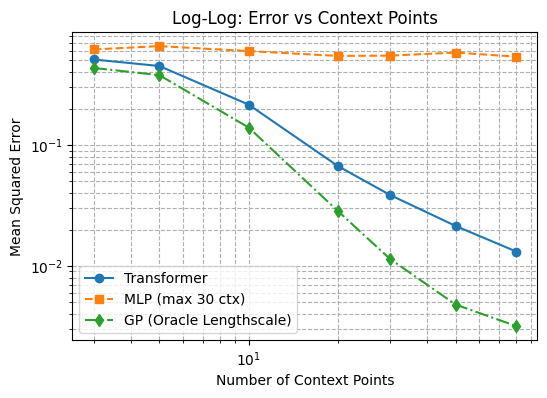

In [12]:
import matplotlib.pyplot as plt

# 1. Test error against the number of context points (3 to 80, log-log)
ctx_sizes = [3, 5, 10, 20, 30, 50, 80]
transformer_errs = []
mlp_errs = []
gp_errs = []

key_test = jax.random.key(999)
for n_c in ctx_sizes:
    key_test, subkey = jax.random.split(key_test)
    # Test on a single large batch to get a stable estimate
    xc_t, yc_t, xt_t, yt_t, ell_t = sample_tasks(subkey, batch=200, n_ctx=n_c, n_tgt=30)

    # Transformer
    t_mean, _ = forward_transformer(params, xc_t, yc_t, xt_t)
    transformer_errs.append(float(((t_mean - yt_t)**2).mean()))

    # MLP (requires clipping context to max 30 as trained)
    m_mean, _ = forward_mlp(mlp_params, xc_t[:, :min(n_c, 30)], yc_t[:, :min(n_c, 30)], xt_t)
    mlp_errs.append(float(((m_mean - yt_t)**2).mean()))

    # GP
    gp_mean, _ = gp_posterior(xc_t, yc_t, xt_t, ell_t)
    gp_errs.append(float(((gp_mean - yt_t)**2).mean()))

plt.figure(figsize=(6, 4))
plt.loglog(ctx_sizes, transformer_errs, 'o-', label='Transformer')
plt.loglog(ctx_sizes, mlp_errs, 's--', label='MLP (max 30 ctx)')
plt.loglog(ctx_sizes, gp_errs, 'd-.', label='GP (Oracle Lengthscale)')
plt.xlabel('Number of Context Points')
plt.ylabel('Mean Squared Error')
plt.title('Log-Log: Error vs Context Points')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

In [37]:
import matplotlib.pyplot as plt
import optax
import jax
import jax.numpy as jnp

ctx_sizes = [3, 5, 10, 20, 30, 50, 80]
target_iterations = [1000, 5000, 10000]

# Data storage for deviations
transformer_results = {steps: [] for steps in target_iterations}
mlp_results = {steps: [] for steps in target_iterations}

# Fixed test key for reproducible evaluation
key_test = jax.random.key(777)

for max_steps in target_iterations:
    print(f"--- Training models for {max_steps} iterations ---")

    # 1. Train Transformer
    key_t = jax.random.key(42)
    t_params = init_transformer_params(key_t)
    lr_sched_t = optax.cosine_decay_schedule(init_value=1e-3, decay_steps=max_steps, alpha=1e-2)
    opt_t = optax.adam(lr_sched_t)
    opt_state_t = opt_t.init(t_params)

    @jax.jit
    def step_t(p, opt_st, xc_, yc_, xt_, yt_, mask_):
        loss, grads = jax.value_and_grad(loss_fn)(p, xc_, yc_, xt_, yt_, mask_)
        updates, opt_st = opt_t.update(grads, opt_st)
        return optax.apply_updates(p, updates), opt_st

    t_key = jax.random.key(101)
    for s in range(max_steps + 1):
        t_key, subkey = jax.random.split(t_key)
        n_c = int(jax.random.randint(subkey, (), 3, 30))
        xc_raw, yc_raw, xt, yt, _ = sample_tasks(subkey, batch=64, n_ctx=n_c, n_tgt=30)
        pad_len = 30 - n_c
        xc = jnp.pad(xc_raw, ((0, 0), (0, pad_len)))
        yc = jnp.pad(yc_raw, ((0, 0), (0, pad_len)))
        mask = jnp.pad(jnp.ones_like(xc_raw, dtype=jnp.bool_), ((0, 0), (0, pad_len)), constant_values=False)
        t_params, opt_state_t = step_t(t_params, opt_state_t, xc, yc, xt, yt, mask)

    # 2. Train MLP
    key_m = jax.random.key(123)
    m_params = init_mlp_params(key_m, input_dim=91)
    opt_m = optax.adam(1e-3)
    opt_state_m = opt_m.init(m_params)

    @jax.jit
    def step_m(p, opt_st, xc_, yc_, xt_, yt_):
        loss, grads = jax.value_and_grad(mlp_loss_fn)(p, xc_, yc_, xt_, yt_)
        updates, opt_st = opt_m.update(grads, opt_st)
        return optax.apply_updates(p, updates), opt_st

    m_key = jax.random.key(201)
    for s in range(max_steps + 1):
        m_key, subkey = jax.random.split(m_key)
        n_c = int(jax.random.randint(subkey, (), 3, 30))
        xc, yc, xt, yt, _ = sample_tasks(subkey, batch=64, n_ctx=n_c, n_tgt=30)
        m_params, opt_state_m = step_m(m_params, opt_state_m, xc, yc, xt, yt)

    # Evaluation across all context sizes
    loop_key = key_test
    for n_c in ctx_sizes:
        loop_key, subkey = jax.random.split(loop_key)
        xc_t, yc_t, xt_t, yt_t, ell_t = sample_tasks(subkey, batch=300, n_ctx=n_c, n_tgt=30)

        # Compute optimal GP error level
        gp_mean, _ = gp_posterior(xc_t, yc_t, xt_t, ell_t)
        gp_mse = float(((gp_mean - yt_t)**2).mean())

        # Compute Transformer error and deviation
        t_mean, _ = forward_transformer(t_params, xc_t, yc_t, xt_t)
        t_mse = float(((t_mean - yt_t)**2).mean())
        transformer_results[max_steps].append(t_mse - gp_mse)

        # Compute MLP error and deviation
        m_mean, _ = forward_mlp(m_params, xc_t[:, :min(n_c, 30)], yc_t[:, :min(n_c, 30)], xt_t)
        m_mse = float(((m_mean - yt_t)**2).mean())
        mlp_results[max_steps].append(m_mse - gp_mse)

print("Evaluation finished! Plotting chart...")

--- Training models for 1000 iterations ---
--- Training models for 5000 iterations ---
--- Training models for 10000 iterations ---
Evaluation finished! Plotting chart...


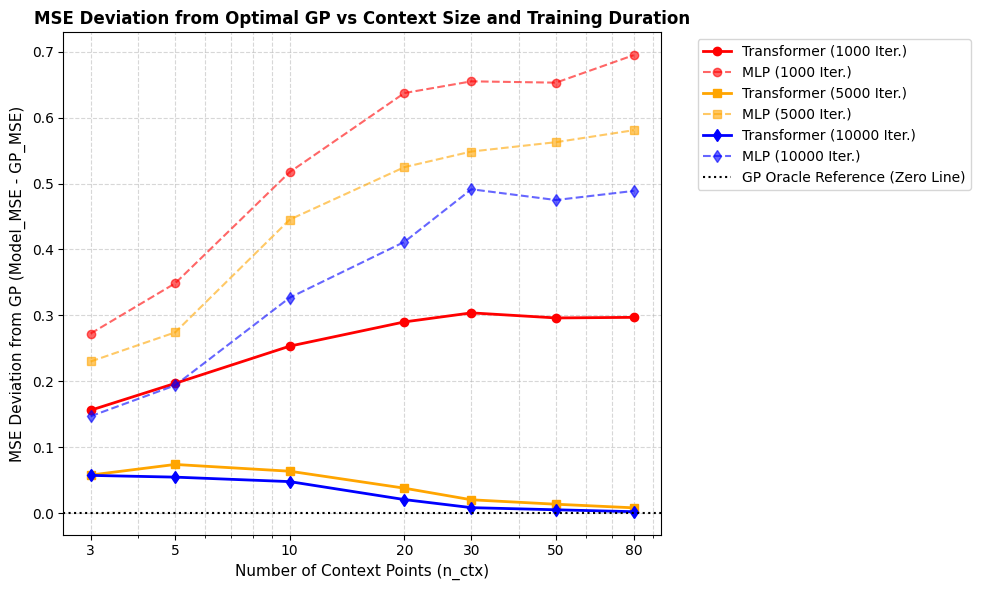

In [38]:
# Plotting the MSE deviations from the GP for different training iterations
plt.figure(figsize=(10, 6))

colors = {1000: 'red', 5000: 'orange', 10000: 'blue'}
markers = {1000: 'o', 5000: 's', 10000: 'd'}

for steps in target_iterations:
    plt.plot(ctx_sizes, transformer_results[steps],
             marker=markers[steps], color=colors[steps], linestyle='-', linewidth=2,
             label=f'Transformer ({steps} Iter.)')
    plt.plot(ctx_sizes, mlp_results[steps],
             marker=markers[steps], color=colors[steps], linestyle='--', alpha=0.6,
             label=f'MLP ({steps} Iter.)')

plt.axhline(0, color='black', linestyle=':', label='GP Oracle Reference (Zero Line)')
plt.xlabel('Number of Context Points (n_ctx)', fontsize=11)
plt.ylabel('MSE Deviation from GP (Model_MSE - GP_MSE)', fontsize=11)
plt.title('MSE Deviation from Optimal GP vs Context Size and Training Duration', fontsize=12, fontweight='bold')
plt.xscale('log')
plt.yscale('linear')
plt.xticks(ctx_sizes, labels=[str(x) for x in ctx_sizes])
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

In [13]:
# 2. Shuffling context points permutation analysis
key_test, subkey = jax.random.split(key_test)
xc_t, yc_t, xt_t, yt_t, _ = sample_tasks(subkey, batch=1, n_ctx=15, n_tgt=30)

# Standard Evaluation
t_mean_orig, _ = forward_transformer(params, xc_t, yc_t, xt_t)

# Shuffle/Permute the context indices
perm = jax.random.permutation(subkey, jnp.arange(15))
xc_shuffled = xc_t[:, perm]
yc_shuffled = yc_t[:, perm]

t_mean_shuffled, _ = forward_transformer(params, xc_shuffled, yc_shuffled, xt_t)

print("=== Permutation Invariance Test ===")
print("Original outputs:", t_mean_orig[0, :5])
print("Shuffled outputs:", t_mean_shuffled[0, :5])
print("Max difference:", float(jnp.abs(t_mean_orig - t_mean_shuffled).max()))

=== Permutation Invariance Test ===
Original outputs: [ 1.7758569  -0.39574537  1.3300083   0.7711184  -0.3293179 ]
Shuffled outputs: [ 1.7758566  -0.3957456   1.3300081   0.77112025 -0.32931766]
Max difference: 1.8477439880371094e-06


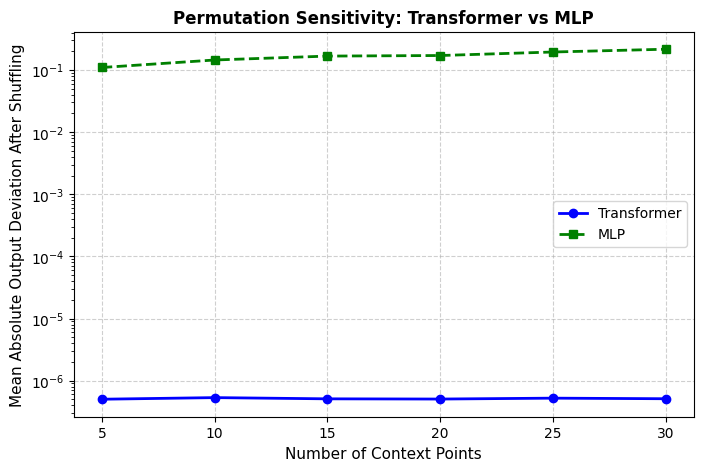

In [15]:
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

# Context sizes to evaluate
shuffle_ctx_sizes = [5, 10, 15, 20, 25, 30]
t_max_diffs = []
m_max_diffs = []

key_shuf = jax.random.key(12345)

for n_c in shuffle_ctx_sizes:
    key_shuf, subkey = jax.random.split(key_shuf)
    # Sample a batch of tasks
    xc_t, yc_t, xt_t, yt_t, _ = sample_tasks(subkey, batch=100, n_ctx=n_c, n_tgt=30)

    # 1. Original Predictions
    t_mean_orig, _ = forward_transformer(params, xc_t, yc_t, xt_t)
    m_mean_orig, _ = forward_mlp(mlp_params, xc_t, yc_t, xt_t)

    # 2. Shuffle context points for each batch element independently
    xc_shuf_list = []
    yc_shuf_list = []
    for i in range(100):
        key_shuf, p_key = jax.random.split(key_shuf)
        perm = jax.random.permutation(p_key, jnp.arange(n_c))
        xc_shuf_list.append(xc_t[i, perm])
        yc_shuf_list.append(yc_t[i, perm])

    xc_t_shuf = jnp.stack(xc_shuf_list, axis=0)
    yc_t_shuf = jnp.stack(yc_shuf_list, axis=0)

    # 3. Shuffled Predictions
    t_mean_shuf, _ = forward_transformer(params, xc_t_shuf, yc_t_shuf, xt_t)
    m_mean_shuf, _ = forward_mlp(mlp_params, xc_t_shuf, yc_t_shuf, xt_t)

    # Calculate mean absolute difference induced by shuffling
    t_diff = float(jnp.abs(t_mean_orig - t_mean_shuf).mean())
    m_diff = float(jnp.abs(m_mean_orig - m_mean_shuf).mean())

    t_max_diffs.append(t_diff)
    m_max_diffs.append(m_diff)

# Plot the results
plt.figure(figsize=(8, 5))
plt.plot(shuffle_ctx_sizes, t_max_diffs, 'o-', color='blue', linewidth=2, label='Transformer')
plt.plot(shuffle_ctx_sizes, m_max_diffs, 's--', color='green', linewidth=2, label='MLP')
plt.xlabel('Number of Context Points', fontsize=11)
plt.ylabel('Mean Absolute Output Deviation After Shuffling', fontsize=11)
plt.title('Permutation Sensitivity: Transformer vs MLP', fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)
plt.yscale('log')
plt.show()

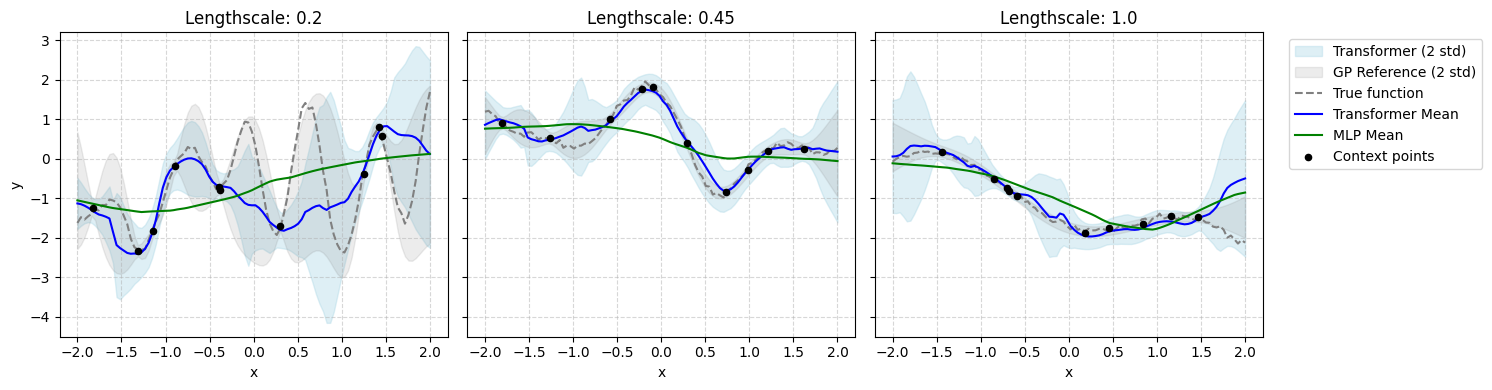

In [23]:
# 3. Visualizing Predictions and Posterior Confidence Bands across multiple lengthscales
grid_x = jnp.linspace(-X_MAX, X_MAX, 100)[None, :]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

key_plot = jax.random.key(1)
for ax, ell_val in zip(axes, [0.2, 0.45, 1.0]):
    key_plot, subkey = jax.random.split(key_plot)
    # Sample identical data setup as cell 3
    xc_t, yc_t, xt_t, yt_t, _ = sample_tasks(subkey, batch=1, n_ctx=10, ell=ell_val, x_tgt=grid_x)

    # Model Predictions
    t_mean, t_logvar = forward_transformer(params, xc_t, yc_t, grid_x)
    t_std = jnp.sqrt(jnp.exp(t_logvar))

    m_mean, m_logvar = forward_mlp(mlp_params, xc_t, yc_t, grid_x)
    m_std = jnp.sqrt(jnp.exp(m_logvar))

    # Exact GP Reference
    gp_mean, gp_cov = gp_posterior(xc_t, yc_t, grid_x, ell_val)
    gp_std = jnp.sqrt(jnp.diagonal(gp_cov[0]))

    # Plotting
    ax.fill_between(grid_x[0], t_mean[0] - 2 * t_std[0], t_mean[0] + 2 * t_std[0], color='lightblue', alpha=0.4, label='Transformer (2 std)')
    ax.fill_between(grid_x[0], gp_mean[0] - 2 * gp_std, gp_mean[0] + 2 * gp_std, color='grey', alpha=0.15, label='GP Reference (2 std)')

    ax.plot(grid_x[0], yt_t[0], color='grey', linestyle='--', label='True function')
    ax.plot(grid_x[0], t_mean[0], color='blue', lw=1.5, label='Transformer Mean')
    ax.plot(grid_x[0], m_mean[0], color='green', lw=1.5, label='MLP Mean')
    ax.scatter(xc_t[0], yc_t[0], color='black', zorder=5, s=20, label='Context points')

    ax.set_title(f"Lengthscale: {ell_val}")
    ax.set_xlabel("x")
    ax.grid(True, linestyle='--', alpha=0.5)

axes[0].set_ylabel("y")
axes[2].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

---
## 5. Flow matching

Now generate posteriors over functions. Target tokens carry a noisy value $y_t$ instead of 0, the time $t$ is embedded and added
to every token, and the head outputs one velocity per target. Same network as before.

Train on the straight path from noise $\epsilon \sim \mathcal{N}(0, 1)$ to data:

$$y_t = (1-t)\,\epsilon + t\,y, \qquad \mathcal{L} = \big\| v_\theta(y_t, t \mid \text{context}) - (y - \epsilon) \big\|^2$$

Sample by integrating $dy/dt = v_\theta$ from $t=0$ to $1$ with Euler, 50 steps.

### 5.1 Flow Matching Model and Loss Function Definition
Here, we adapt our transformer from before to accept a time scalar $t$ and noisy target values $y_t$ in order to predict the target velocity $v = y - \epsilon$.

In [24]:
import jax
import jax.numpy as jnp
import optax

def time_embedding(t, d_model=64):
    """Embed time t scalar into a representation vector of size d_model"""
    # Sinusoidal time embedding
    frequencies = jnp.exp(jnp.arange(0, d_model, 2) * -(jnp.log(10000.0) / d_model))
    angles = t[:, None] * frequencies[None, :]
    embedding = jnp.concatenate([jnp.sin(angles), jnp.cos(angles)], axis=-1)
    return embedding

def fm_forward_transformer(params, xc, yc, xt, yt_noisy, t, active_ctx_mask=None):
    b, n_ctx = xc.shape
    n_tgt = xt.shape[1]

    # Embed time scalar
    t_embed = time_embedding(t, d_model=64)  # (b, d_model)

    # Input tokens are represented by: [x, y, is_context]
    ctx_tokens = jnp.stack([xc, yc, jnp.ones_like(xc)], axis=-1)
    tgt_tokens = jnp.stack([xt, yt_noisy, jnp.zeros_like(xt)], axis=-1)
    tokens = jnp.concatenate([ctx_tokens, tgt_tokens], axis=1)

    # Project to d_model
    h = jnp.dot(tokens, params['embed_w1']) + params['embed_b1']
    h = jax.nn.relu(h)
    h = jnp.dot(h, params['embed_w2']) + params['embed_b2']

    # Add time embedding to all tokens
    h = h + t_embed[:, None, :]

    # Self-attention mask (target-to-target connections must be isolated/diagonalized)
    n_total = n_ctx + n_tgt
    mask = jnp.ones((b, n_total, n_total), dtype=jnp.bool_)
    mask = mask.at[:, n_ctx:, n_ctx:].set(jnp.eye(n_tgt, dtype=jnp.bool_))

    if active_ctx_mask is not None:
        mask = mask.at[:, :, :n_ctx].set(active_ctx_mask[:, None, :])

    for layer in params['layers']:
        h = transformer_block(layer, h, mask=mask)

    # Read out a single velocity scalar per target point
    tgt_outputs = h[:, n_ctx:]
    velocity_pred = jnp.dot(tgt_outputs, params['velocity_head_w']) + params['velocity_head_b']
    return velocity_pred[..., 0]

def fm_loss_fn(params, xc, yc, xt, yt, key):
    b, n_ctx = xc.shape
    n_tgt = xt.shape[1]

    # Sample random time t in [0, 1]
    k_t, k_eps = jax.random.split(key)
    t = jax.random.uniform(k_t, (b,))

    # Sample noise eps
    eps = jax.random.normal(k_eps, yt.shape)

    # Interpolated trajectory: y_t = (1-t)*eps + t*y
    t_expanded = t[:, None]
    yt_noisy = (1.0 - t_expanded) * eps + t_expanded * yt

    # Target velocity vector
    target_velocity = yt - eps

    # Forward prediction
    vel_pred = fm_forward_transformer(params, xc, yc, xt, yt_noisy, t)

    # Mean squared error loss
    return jnp.mean((vel_pred - target_velocity) ** 2)

### 5.2 Euler Integration Sampler
Here we implement the integration code to sample paths from the prior distribution at $t=0$ to the posterior distribution at $t=1$ in 50 discrete steps.

In [25]:
def sample_posterior_fm(params, xc, yc, xt, key, num_steps=50):
    """Generates posterior function values xt by integrating velocity field dy/dt = v_theta"""
    b = xc.shape[0]
    n_tgt = xt.shape[1]

    # Start from pure Gaussian noise at t=0
    y_t = jax.random.normal(key, (b, n_tgt))
    dt = 1.0 / num_steps

    for step in range(num_steps):
        t_val = step / num_steps
        t = jnp.full((b,), t_val)

        # Compute velocity prediction
        v = fm_forward_transformer(params, xc, yc, xt, y_t, t)

        # Euler step update
        y_t = y_t + v * dt

    return y_t

### 5.3 Model Initialization and Training Loop
Let's initialize the parameters including our new `velocity_head_w` and `velocity_head_b`, set up the Adam optimizer, and train the flow matching network.

In [26]:
def init_flow_matching_params(key, d_model=64, num_layers=4, mlp_dim=256):
    keys = jax.random.split(key, 13)
    params = {}

    # Non-linear embedding projection
    params['embed_w1'] = jax.random.normal(keys[0], (3, 64)) * jnp.sqrt(2.0 / 3)
    params['embed_b1'] = jnp.zeros((64,))
    params['embed_w2'] = jax.random.normal(keys[1], (64, d_model)) * jnp.sqrt(2.0 / 64)
    params['embed_b2'] = jnp.zeros((d_model,))

    # Transformer Blocks
    layers = []
    for i in range(num_layers):
        layer_key = jax.random.split(keys[i+2], 8)
        layer = {
            'gamma1': jnp.ones((d_model,)), 'beta1': jnp.zeros((d_model,)),
            'gamma2': jnp.ones((d_model,)), 'beta2': jnp.zeros((d_model,)),
            'attn': {
                'w_q': jax.random.normal(layer_key[0], (d_model, d_model)) * jnp.sqrt(1.0 / d_model),
                'w_k': jax.random.normal(layer_key[1], (d_model, d_model)) * jnp.sqrt(1.0 / d_model),
                'w_v': jax.random.normal(layer_key[2], (d_model, d_model)) * jnp.sqrt(1.0 / d_model),
                'w_o': jax.random.normal(layer_key[3], (d_model, d_model)) * jnp.sqrt(1.0 / d_model)
            },
            'w_ff1': jax.random.normal(layer_key[4], (d_model, mlp_dim)) * jnp.sqrt(2.0 / d_model),
            'b_ff1': jnp.zeros((mlp_dim,)),
            'w_ff2': jax.random.normal(layer_key[5], (mlp_dim, d_model)) * jnp.sqrt(2.0 / mlp_dim),
            'b_ff2': jnp.zeros((d_model,))
        }
        layers.append(layer)
    params['layers'] = layers

    # Readout head outputs a single velocity dimension (mean-like direction)
    params['velocity_head_w'] = jax.random.normal(keys[-1], (d_model, 1)) * jnp.sqrt(2.0 / d_model)
    params['velocity_head_b'] = jnp.zeros((1,))
    return params

# Initialize FM Parameters
fm_key = jax.random.key(2025)
fm_params = init_flow_matching_params(fm_key)

fm_total_steps = 5000
fm_lr_schedule = optax.cosine_decay_schedule(init_value=1e-3, decay_steps=fm_total_steps, alpha=1e-2)
fm_opt = optax.adam(fm_lr_schedule)
fm_opt_state = fm_opt.init(fm_params)

@jax.jit
def fm_update_step(params, opt_state, xc, yc, xt, yt, key):
    loss, grads = jax.value_and_grad(fm_loss_fn)(params, xc, yc, xt, yt, key)
    updates, opt_state = fm_opt.update(grads, opt_state)
    new_params = optax.apply_updates(params, updates)
    return new_params, opt_state, loss

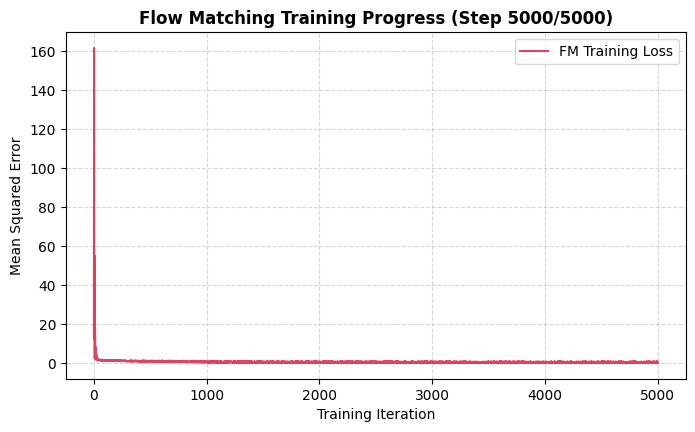

Step    0 | FM MSE Loss: 12.6283
Step  200 | FM MSE Loss: 1.1499
Step  400 | FM MSE Loss: 1.1736
Step  600 | FM MSE Loss: 1.2550
Step  800 | FM MSE Loss: 0.9408
Step 1000 | FM MSE Loss: 0.5474
Step 1200 | FM MSE Loss: 0.6704
Step 1400 | FM MSE Loss: 0.3842
Step 1600 | FM MSE Loss: 0.5410
Step 1800 | FM MSE Loss: 0.2833
Step 2000 | FM MSE Loss: 0.3466
Step 2200 | FM MSE Loss: 0.5274
Step 2400 | FM MSE Loss: 0.2928
Step 2600 | FM MSE Loss: 1.1288
Step 2800 | FM MSE Loss: 0.3435
Step 3000 | FM MSE Loss: 0.3532
Step 3200 | FM MSE Loss: 0.8570
Step 3400 | FM MSE Loss: 0.3666
Step 3600 | FM MSE Loss: 0.3117
Step 3800 | FM MSE Loss: 0.3827
Step 4000 | FM MSE Loss: 0.2970
Step 4200 | FM MSE Loss: 0.2858
Step 4400 | FM MSE Loss: 0.2788
Step 4600 | FM MSE Loss: 0.6953
Step 4800 | FM MSE Loss: 0.3210
Step 5000 | FM MSE Loss: 0.2582


In [27]:
from IPython import display

fm_steps = []
fm_losses = []
fm_log_history = []

print("Starting Flow Matching training...")
for step in range(fm_total_steps + 1):
    fm_key, subkey = jax.random.split(fm_key)
    n_ctx = int(jax.random.randint(subkey, (), 3, 30))
    xc, yc, xt, yt, _ = sample_tasks(subkey, batch=64, n_ctx=n_ctx, n_tgt=30)

    fm_params, fm_opt_state, loss_val = fm_update_step(fm_params, fm_opt_state, xc, yc, xt, yt, subkey)

    fm_steps.append(step)
    fm_losses.append(float(loss_val))

    if step % 200 == 0 or step == fm_total_steps:
        fm_log_history.append(f"Step {step:4d} | FM MSE Loss: {loss_val:.4f}")
        display.clear_output(wait=True)
        plt.figure(figsize=(8, 4.5))
        plt.plot(fm_steps, fm_losses, color='crimson', alpha=0.8, label='FM Training Loss')
        plt.xlabel('Training Iteration')
        plt.ylabel('Mean Squared Error')
        plt.title(f'Flow Matching Training Progress (Step {step}/{fm_total_steps})', fontsize=12, fontweight='bold')
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.legend()
        plt.show()

        for line in fm_log_history:
            print(line)

### 5.4 Sampling and Posterior Function Visualization
We draw 25 trajectory samples from our Flow Matching posterior and evaluate them across three lengthscales against the analytical GP reference bands.

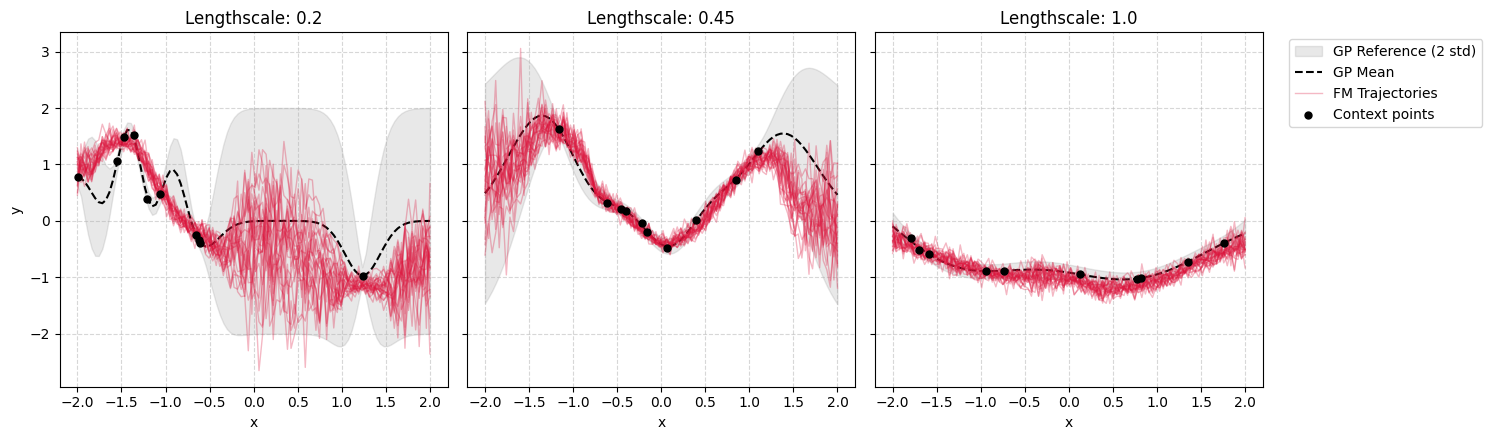

In [28]:
import matplotlib.pyplot as plt

grid_x = jnp.linspace(-X_MAX, X_MAX, 100)[None, :]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

key_fm_plot = jax.random.key(999)
for ax, ell_val in zip(axes, [0.2, 0.45, 1.0]):
    key_fm_plot, subkey = jax.random.split(key_fm_plot)
    # Sample context points from GP
    xc_t, yc_t, xt_t, yt_t, _ = sample_tasks(subkey, batch=1, n_ctx=10, ell=ell_val, x_tgt=grid_x)

    # Analytical GP Ground Truth
    gp_mean, gp_cov = gp_posterior(xc_t, yc_t, grid_x, ell_val)
    gp_std = jnp.sqrt(jnp.diagonal(gp_cov[0]))

    # Tile context to batch size of 25 for generating 25 parallel flow paths
    xc_tile = jnp.repeat(xc_t, 25, axis=0)
    yc_tile = jnp.repeat(yc_t, 25, axis=0)
    grid_tile = jnp.repeat(grid_x, 25, axis=0)

    key_fm_plot, sample_key = jax.random.split(key_fm_plot)
    samples = sample_posterior_fm(fm_params, xc_tile, yc_tile, grid_tile, sample_key, num_steps=50)

    # Plotting
    ax.fill_between(grid_x[0], gp_mean[0] - 2 * gp_std, gp_mean[0] + 2 * gp_std, color='grey', alpha=0.18, label='GP Reference (2 std)')
    ax.plot(grid_x[0], gp_mean[0], color='black', lw=1.5, linestyle='--', label='GP Mean')

    # Plot the individual Flow Matching trajectories
    for idx in range(25):
        label = 'FM Trajectories' if idx == 0 else ""
        ax.plot(grid_x[0], samples[idx], color='crimson', alpha=0.3, lw=1.0, label=label)

    ax.scatter(xc_t[0], yc_t[0], color='black', zorder=5, s=25, label='Context points')
    ax.set_title(f"Lengthscale: {ell_val}")
    ax.set_xlabel("x")
    ax.grid(True, linestyle='--', alpha=0.5)

axes[0].set_ylabel("y")
axes[2].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [34]:
import matplotlib.animation as animation
from IPython.display import HTML
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

# Adjust matplotlib parameters to allow larger embedding size
plt.rcParams['animation.embed_limit'] = 50.0

# Prepare data for three lengthscales: 0.2, 0.45, and 1.0
lengthscales = [0.2, 0.45, 1.0]
num_paths = 15  # Slightly reduced from 20 to manage memory and size
num_steps = 40  # 40 steps is plenty for a smooth visual trajectory
dt = 1.0 / num_steps

key_anim = jax.random.key(12345)

# We will store datasets, GP references, and trajectory histories for all three lengthscales
data_configs = {}

for ell_val in lengthscales:
    key_anim, subkey = jax.random.split(key_anim)

    # Sample context and reference
    xc_t, yc_t, xt_t, yt_t, _ = sample_tasks(subkey, batch=1, n_ctx=10, ell=ell_val, x_tgt=grid_x)
    gp_mean, gp_cov = gp_posterior(xc_t, yc_t, grid_x, ell_val)
    gp_std = jnp.sqrt(jnp.diagonal(gp_cov[0]))

    # Tile context for parallel generative paths
    xc_tile = jnp.repeat(xc_t, num_paths, axis=0)
    yc_tile = jnp.repeat(yc_t, num_paths, axis=0)
    grid_tile = jnp.repeat(grid_x, num_paths, axis=0)

    # Run integration, saving state at each step
    y_history = []
    y_t = jax.random.normal(subkey, (num_paths, grid_x.shape[1]))
    y_history.append(y_t)

    for step in range(num_steps):
        t = jnp.full((num_paths,), step / num_steps)
        v = fm_forward_transformer(fm_params, xc_tile, yc_tile, grid_tile, y_t, t)
        y_t = y_t + v * dt
        y_history.append(y_t)

    data_configs[ell_val] = {
        'xc': xc_t[0], 'yc': yc_t[0],
        'gp_mean': gp_mean[0], 'gp_std': gp_std,
        'y_history': y_history
    }

# Set up the figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.5), sharey=True)
lines_by_subplot = []

for i, ell_val in enumerate(lengthscales):
    ax = axes[i]
    cfg = data_configs[ell_val]

    ax.set_xlim(-X_MAX, X_MAX)
    ax.set_ylim(-3, 3)
    ax.set_xlabel("x")
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_title(f"Lengthscale: {ell_val}")

    # Plot constant background structures (GP reference + observed context points)
    ax.fill_between(grid_x[0], cfg['gp_mean'] - 2 * cfg['gp_std'], cfg['gp_mean'] + 2 * cfg['gp_std'], color='grey', alpha=0.15, label='GP 2 std')
    ax.plot(grid_x[0], cfg['gp_mean'], color='black', lw=1.5, linestyle='--', label='GP Mean')
    ax.scatter(cfg['xc'], cfg['yc'], color='black', zorder=5, s=35, label='Context')

    # Dynamic line holders for trajectories
    lines = [ax.plot([], [], color='crimson', alpha=0.4, lw=1.2)[0] for _ in range(num_paths)]
    lines_by_subplot.append(lines)

axes[0].set_ylabel("y")
axes[2].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

time_text = axes[1].text(0.35, 0.9, '', transform=axes[1].transAxes, fontsize=12, fontweight='bold', bbox=dict(facecolor='white', alpha=0.8))
plt.tight_layout()

def init_anim():
    for lines in lines_by_subplot:
        for line in lines:
            line.set_data([], [])
    time_text.set_text('')
    return [line for lines in lines_by_subplot for line in lines] + [time_text]

def animate(frame):
    for i, ell_val in enumerate(lengthscales):
        cfg = data_configs[ell_val]
        curr_y = cfg['y_history'][frame]
        lines = lines_by_subplot[i]
        for idx, line in enumerate(lines):
            line.set_data(grid_x[0], curr_y[idx])
    time_text.set_text(f"t = {frame/num_steps:.2f}")
    return [line for lines in lines_by_subplot for line in lines] + [time_text]

anim = animation.FuncAnimation(fig, animate, init_func=init_anim, frames=num_steps + 1, interval=100, blit=True)
plt.close()

# Display the animated flow matching across all three lengthscales side-by-side
HTML(anim.to_jshtml())

### Plot Export

In [40]:
# 1. Save Permutation Sensitivity Plot
plt.figure(figsize=(8, 5))
plt.plot(shuffle_ctx_sizes, t_max_diffs, 'o-', color='blue', linewidth=2, label='Transformer')
plt.plot(shuffle_ctx_sizes, m_max_diffs, 's--', color='green', linewidth=2, label='MLP')
plt.xlabel('Number of Context Points')
plt.ylabel('Mean Absolute Output Deviation')
plt.title('Permutation Sensitivity Comparison')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.yscale('log')
plt.savefig('/content/permutation_sensitivity.png', bbox_inches='tight', dpi=150)
plt.close()

# 2. Save Multi-Lengthscale Model Predictions
grid_x = jnp.linspace(-X_MAX, X_MAX, 100)[None, :]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
key_plot = jax.random.key(1)
for ax, ell_val in zip(axes, [0.2, 0.45, 1.0]):
    key_plot, subkey = jax.random.split(key_plot)
    xc_t, yc_t, xt_t, yt_t, _ = sample_tasks(subkey, batch=1, n_ctx=10, ell=ell_val, x_tgt=grid_x)
    t_mean, t_logvar = forward_transformer(params, xc_t, yc_t, grid_x)
    t_std = jnp.sqrt(jnp.exp(t_logvar))
    m_mean, _ = forward_mlp(mlp_params, xc_t, yc_t, grid_x)
    gp_mean, gp_cov = gp_posterior(xc_t, yc_t, grid_x, ell_val)
    gp_std = jnp.sqrt(jnp.diagonal(gp_cov[0]))

    ax.fill_between(grid_x[0], t_mean[0] - 2 * t_std[0], t_mean[0] + 2 * t_std[0], color='lightblue', alpha=0.4)
    ax.fill_between(grid_x[0], gp_mean[0] - 2 * gp_std, gp_mean[0] + 2 * gp_std, color='grey', alpha=0.15)
    ax.plot(grid_x[0], yt_t[0], color='grey', linestyle='--')
    ax.plot(grid_x[0], t_mean[0], color='blue', lw=1.5)
    ax.plot(grid_x[0], m_mean[0], color='green', lw=1.5)
    ax.scatter(xc_t[0], yc_t[0], color='black', zorder=5, s=20)
    ax.set_title(f"Lengthscale: {ell_val}")
    ax.grid(True, linestyle='--', alpha=0.5)

plt.savefig('/content/predictions_multi_lengthscale.png', bbox_inches='tight', dpi=150)
plt.close()

# 3. Save Flow Matching Trajectories
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
key_fm_plot = jax.random.key(999)
for ax, ell_val in zip(axes, [0.2, 0.45, 1.0]):
    key_fm_plot, subkey = jax.random.split(key_fm_plot)
    xc_t, yc_t, xt_t, yt_t, _ = sample_tasks(subkey, batch=1, n_ctx=10, ell=ell_val, x_tgt=grid_x)
    gp_mean, gp_cov = gp_posterior(xc_t, yc_t, grid_x, ell_val)
    gp_std = jnp.sqrt(jnp.diagonal(gp_cov[0]))
    xc_tile = jnp.repeat(xc_t, 25, axis=0)
    yc_tile = jnp.repeat(yc_t, 25, axis=0)
    grid_tile = jnp.repeat(grid_x, 25, axis=0)
    key_fm_plot, sample_key = jax.random.split(key_fm_plot)
    samples = sample_posterior_fm(fm_params, xc_tile, yc_tile, grid_tile, sample_key, num_steps=50)

    ax.fill_between(grid_x[0], gp_mean[0] - 2 * gp_std, gp_mean[0] + 2 * gp_std, color='grey', alpha=0.18)
    ax.plot(grid_x[0], gp_mean[0], color='black', lw=1.5, linestyle='--')
    for idx in range(25):
        ax.plot(grid_x[0], samples[idx], color='crimson', alpha=0.3, lw=1.0)
    ax.scatter(xc_t[0], yc_t[0], color='black', zorder=5, s=25)
    ax.set_title(f"Lengthscale: {ell_val}")
    ax.grid(True, linestyle='--', alpha=0.5)

plt.savefig('/content/flow_matching_trajectories.png', bbox_inches='tight', dpi=150)
plt.close()

# 4. Save the Anim Webpage
with open('/content/flow_matching_animation.html', 'w') as f:
    f.write(anim.to_jshtml())

print("Saved the following items in /content/ workspace directory:")
print(" - /content/permutation_sensitivity.png")
print(" - /content/predictions_multi_lengthscale.png")
print(" - /content/flow_matching_trajectories.png")
print(" - /content/flow_matching_animation.html")

Saved the following items in /content/ workspace directory:
 - /content/permutation_sensitivity.png
 - /content/predictions_multi_lengthscale.png
 - /content/flow_matching_trajectories.png
 - /content/flow_matching_animation.html


In [39]:
import matplotlib.pyplot as plt
import os

# Ensure output directory exists
os.makedirs('/content', exist_ok=True)

# --- 1. Export: Log-Log Error vs Context Points (Section 4) ---
plt.figure(figsize=(7, 5))
plt.loglog(ctx_sizes, transformer_errs, 'o-', color='blue', linewidth=2, label='Transformer')
plt.loglog(ctx_sizes, mlp_errs, 's--', color='green', linewidth=2, label='MLP (max 30 ctx)')
plt.loglog(ctx_sizes, gp_errs, 'd-.', color='black', linewidth=1.5, label='GP (Oracle)')
plt.xlabel('Number of Context Points')
plt.ylabel('Mean Squared Error')
plt.title('Log-Log: Model Error vs Context Points', fontsize=11, fontweight='bold')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.savefig('/content/log_log_error_vs_context.png', bbox_inches='tight', dpi=150)
plt.close()

# --- 2. Export: Training Iterations MSE Deviation Comparison (Section 4) ---
plt.figure(figsize=(10, 6))
colors = {1000: 'red', 5000: 'orange', 10000: 'blue'}
markers = {1000: 'o', 5000: 's', 10000: 'd'}
for steps in target_iterations:
    plt.plot(ctx_sizes, transformer_results[steps],
             marker=markers[steps], color=colors[steps], linestyle='-', linewidth=2,
             label=f'Transformer ({steps} Iter.)')
    plt.plot(ctx_sizes, mlp_results[steps],
             marker=markers[steps], color=colors[steps], linestyle='--', alpha=0.6,
             label=f'MLP ({steps} Iter.)')
plt.axhline(0, color='black', linestyle=':', label='GP Oracle Reference')
plt.xlabel('Number of Context Points (n_ctx)', fontsize=11)
plt.ylabel('MSE Deviation from GP (Model - GP)', fontsize=11)
plt.title('MSE Deviation vs Context Size and Training Duration', fontsize=12, fontweight='bold')
plt.xscale('log')
plt.xticks(ctx_sizes, labels=[str(x) for x in ctx_sizes])
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.savefig('/content/training_duration_comparison.png', bbox_inches='tight', dpi=150)
plt.close()

# --- 3. Export: Permutation Sensitivity (Section 4) ---
plt.figure(figsize=(8, 5))
plt.plot(shuffle_ctx_sizes, t_max_diffs, 'o-', color='blue', linewidth=2, label='Transformer (Attention)')
plt.plot(shuffle_ctx_sizes, m_max_diffs, 's--', color='green', linewidth=2, label='MLP (Flat Input)')
plt.xlabel('Number of Context Points', fontsize=11)
plt.ylabel('Mean Absolute Output Deviation After Shuffling', fontsize=11)
plt.title('Permutation Sensitivity: Transformer vs MLP', fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)
plt.yscale('log')
plt.savefig('/content/permutation_sensitivity.png', bbox_inches='tight', dpi=150)
plt.close()

# --- 4. Export: Multi-Lengthscale Predictions & Confidence Bands (Section 4) ---
grid_x = jnp.linspace(-X_MAX, X_MAX, 100)[None, :]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
key_plot = jax.random.key(1)
for ax, ell_val in zip(axes, [0.2, 0.45, 1.0]):
    key_plot, subkey = jax.random.split(key_plot)
    xc_t, yc_t, xt_t, yt_t, _ = sample_tasks(subkey, batch=1, n_ctx=10, ell=ell_val, x_tgt=grid_x)
    t_mean, t_logvar = forward_transformer(params, xc_t, yc_t, grid_x)
    t_std = jnp.sqrt(jnp.exp(t_logvar))
    m_mean, _ = forward_mlp(mlp_params, xc_t, yc_t, grid_x)
    gp_mean, gp_cov = gp_posterior(xc_t, yc_t, grid_x, ell_val)
    gp_std = jnp.sqrt(jnp.diagonal(gp_cov[0]))

    ax.fill_between(grid_x[0], t_mean[0] - 2 * t_std[0], t_mean[0] + 2 * t_std[0], color='lightblue', alpha=0.4, label='Transformer 2 std')
    ax.fill_between(grid_x[0], gp_mean[0] - 2 * gp_std, gp_mean[0] + 2 * gp_std, color='grey', alpha=0.15, label='GP Reference')
    ax.plot(grid_x[0], yt_t[0], color='grey', linestyle='--')
    ax.plot(grid_x[0], t_mean[0], color='blue', lw=1.5)
    ax.plot(grid_x[0], m_mean[0], color='green', lw=1.5)
    ax.scatter(xc_t[0], yc_t[0], color='black', zorder=5, s=20)
    ax.set_title(f"Lengthscale: {ell_val}")
    ax.grid(True, linestyle='--', alpha=0.5)
axes[0].set_ylabel("y")
plt.savefig('/content/predictions_multi_lengthscale.png', bbox_inches='tight', dpi=150)
plt.close()

# --- 5. Export: Flow Matching Trajectories (Section 5) ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
key_fm_plot = jax.random.key(999)
for ax, ell_val in zip(axes, [0.2, 0.45, 1.0]):
    key_fm_plot, subkey = jax.random.split(key_fm_plot)
    xc_t, yc_t, xt_t, yt_t, _ = sample_tasks(subkey, batch=1, n_ctx=10, ell=ell_val, x_tgt=grid_x)
    gp_mean, gp_cov = gp_posterior(xc_t, yc_t, grid_x, ell_val)
    gp_std = jnp.sqrt(jnp.diagonal(gp_cov[0]))
    xc_tile = jnp.repeat(xc_t, 25, axis=0)
    yc_tile = jnp.repeat(yc_t, 25, axis=0)
    grid_tile = jnp.repeat(grid_x, 25, axis=0)
    key_fm_plot, sample_key = jax.random.split(key_fm_plot)
    samples = sample_posterior_fm(fm_params, xc_tile, yc_tile, grid_tile, sample_key, num_steps=50)

    ax.fill_between(grid_x[0], gp_mean[0] - 2 * gp_std, gp_mean[0] + 2 * gp_std, color='grey', alpha=0.18, label='GP Reference')
    ax.plot(grid_x[0], gp_mean[0], color='black', lw=1.5, linestyle='--')
    for idx in range(25):
        ax.plot(grid_x[0], samples[idx], color='crimson', alpha=0.3, lw=1.0)
    ax.scatter(xc_t[0], yc_t[0], color='black', zorder=5, s=25)
    ax.set_title(f"Lengthscale: {ell_val}")
    ax.grid(True, linestyle='--', alpha=0.5)
axes[0].set_ylabel("y")
plt.savefig('/content/flow_matching_trajectories.png', bbox_inches='tight', dpi=150)
plt.close()

# --- 6. Export: Live Flow Matching Trajectory Animation (Section 5) ---
with open('/content/flow_matching_animation.html', 'w') as f:
    f.write(anim.to_jshtml())

print("=== All visualizations successfully exported to /content/ workspace directory ===")
for filename in sorted(os.listdir('/content')):
    if filename.endswith(('.png', '.html')):
        print(f"  [Saved] -> /content/{filename}")

=== All visualizations successfully exported to /content/ workspace directory ===
  [Saved] -> /content/flow_matching_animation.html
  [Saved] -> /content/flow_matching_trajectories.png
  [Saved] -> /content/log_log_error_vs_context.png
  [Saved] -> /content/permutation_sensitivity.png
  [Saved] -> /content/predictions_multi_lengthscale.png
  [Saved] -> /content/training_duration_comparison.png
